# Zero-shot variant effect prediction with ESM-2

**Question:** a protein language model is trained only to fill in masked amino acids in natural sequences.
It never sees a fitness measurement. Can it still tell which mutations break a protein?

**Approach (no training, no labels):**

1. For every position *i* of the wild-type sequence, replace residue *i* with `<mask>` and run ESM-2.
2. Read off the model's probability for each of the 20 amino acids at that position.
3. Score a substitution `wt → mt` at *i* with the **masked-marginal log-likelihood ratio**

$$\text{score}(wt_i \to mt_i) = \log p(x_i = mt \mid x_{-i}) - \log p(x_i = wt \mid x_{-i})$$

   Negative = the model finds the mutant *less* plausible than wild type → predicted damaging.
4. Compare the scores with a **deep mutational scanning (DMS)** experiment from **ProteinGym** using Spearman's ρ.

Sections: 0 setup · 1 data · 2 scoring · 3 benchmark on β-lactamase · 4 what the model gets right (positions vs substitutions) · 5 model size · 6 cheaper scoring + baselines · 7 nine more assays · 8 takeaways

## 0. Setup

In [1]:
from pathlib import Path
import io, time, zipfile, warnings

import numpy as np
import pandas as pd
import requests
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from transformers import AutoTokenizer, EsmForMaskedLM
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
torch.manual_seed(0)
DATA = Path("data"); DATA.mkdir(exist_ok=True)
SCORES = DATA / "scores"; SCORES.mkdir(exist_ok=True)
FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(4)
print("device:", device, "| torch", torch.__version__)

# ESM-2 checkpoints (Hugging Face). Full-sequence scan time on this CPU for a 286-aa protein:
#   8M ≈ 15 s, 35M ≈ 50 s, 150M ≈ 3 min, 650M ≈ 9 min (cached to data/scores after the first run).
MODELS = {
    "8M":   "facebook/esm2_t6_8M_UR50D",
    "35M":  "facebook/esm2_t12_35M_UR50D",
    "150M": "facebook/esm2_t30_150M_UR50D",
    "650M": "facebook/esm2_t33_650M_UR50D",
}
MAIN_MODEL = "35M"
MAIN_ASSAY = "BLAT_ECOLX_Stiffler_2015"   # TEM-1 β-lactamase, ampicillin resistance (E. coli)
RUN_650M = True                           # set False to skip the ~9-min 650M scan in §5

# Plot colors: categorical slots 1/2, diverging red ↔ gray ↔ blue (low ↔ high fitness)
C1, C2, MUTED = "#2a78d6", "#eb6834", "#898781"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "figure.dpi": 110})
AAS = list("ACDEFGHIKLMNPQRSTVWY")

/Users/ynewton/whisker_dx_related/whisker_dx/glm_test/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | torch 2.2.2


## 1. Data: ProteinGym

[ProteinGym](https://proteingym.org) (Notin et al., 2023) is the standard benchmark for variant effect predictors.
It packages 217 DMS assays in a common format — one CSV per assay with columns `mutant` (e.g. `H24C`, 1-based position),
`DMS_score` (higher = fitter) and `DMS_score_bin` (1 = fit, 0 = not fit) — plus a reference table with each assay's wild-type
sequence, and published zero-shot scores for ~90 models. We use the published ESM-2 numbers to **check our implementation**.

Downloads (cached under `data/`): the reference table and leaderboard from GitHub (~0.4 MB), and the substitutions zip (43 MB)
from which we extract only the assays we use.

In [2]:
PG_RAW = "https://raw.githubusercontent.com/OATML-Markslab/ProteinGym/main"
PG_ZIP = "https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip"

def fetch(url, path):
    if not path.exists():
        print("downloading", url)
        r = requests.get(url, timeout=600); r.raise_for_status()
        path.write_bytes(r.content)
    return path

ref = pd.read_csv(fetch(f"{PG_RAW}/reference_files/DMS_substitutions.csv", DATA / "DMS_substitutions.csv"))
published = pd.read_csv(fetch(f"{PG_RAW}/benchmarks/DMS_zero_shot/substitutions/Spearman/"
                              "DMS_substitutions_Spearman_DMS_level.csv", DATA / "published_spearman.csv"))
published = published.rename(columns={"DMS ID": "DMS_id"}).set_index("DMS_id")
ref = ref.set_index("DMS_id")
print(len(ref), "assays in ProteinGym")

def load_assay(dms_id):
    # Extract one assay CSV from the zip (zip is downloaded once and kept).
    out = DATA / "dms" / f"{dms_id}.csv"
    if not out.exists():
        z = fetch(PG_ZIP, DATA / "DMS_ProteinGym_substitutions.zip")
        out.parent.mkdir(exist_ok=True)
        with zipfile.ZipFile(z) as zf:
            out.write_bytes(zf.read(f"DMS_ProteinGym_substitutions/{dms_id}.csv"))
    df = pd.read_csv(out)
    df = df[~df["mutant"].str.contains(":")].copy()          # single substitutions only
    df["wt"] = df["mutant"].str[0]
    df["pos"] = df["mutant"].str[1:-1].astype(int)          # 1-based
    df["mt"] = df["mutant"].str[-1]
    return df

wt_seq = ref.loc[MAIN_ASSAY, "target_seq"]
dms = load_assay(MAIN_ASSAY)
print(MAIN_ASSAY, "|", ref.loc[MAIN_ASSAY, "molecule_name"], "|", ref.loc[MAIN_ASSAY, "selection_assay"])
print(f"length {len(wt_seq)} aa, {len(dms)} single mutants "
      f"({len(dms) / (19 * len(wt_seq)):.0%} of all {19 * len(wt_seq)} possible)")
dms.head()

217 assays in ProteinGym
BLAT_ECOLX_Stiffler_2015 | Beta-lactamase TEM | Growth (10-2500 ug/mL ampicillin)
length 286 aa, 4996 single mutants (92% of all 5434 possible)


,mutant,mutated_sequence,DMS_score,DMS_score_bin,wt,pos,mt
0,H24C,MSIQHFRVALIPFFAAFCLPVFACPETLVKVKDAEDQLGARVGYIE...,-0.418260,1,H,24,C
1,H24Y,MSIQHFRVALIPFFAAFCLPVFAYPETLVKVKDAEDQLGARVGYIE...,-0.885025,1,H,24,Y
2,H24W,MSIQHFRVALIPFFAAFCLPVFAWPETLVKVKDAEDQLGARVGYIE...,-1.347586,0,H,24,W
3,H24V,MSIQHFRVALIPFFAAFCLPVFAVPETLVKVKDAEDQLGARVGYIE...,-0.026874,1,H,24,V
4,H24T,MSIQHFRVALIPFFAAFCLPVFATPETLVKVKDAEDQLGARVGYIE...,-0.067188,1,H,24,T


**Sanity check before scoring anything:** the wild-type letter in every `mutant` string must match the reference sequence at that
position. An off-by-one here (0- vs 1-based, or a signal-peptide offset) silently produces near-zero correlations.

all wild-type residues match


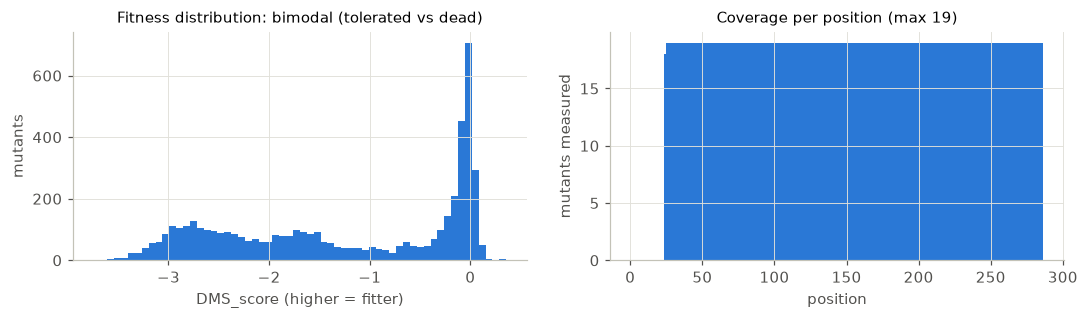

In [3]:
def check_wt(df, seq):
    bad = df[[seq[p - 1] != w for p, w in zip(df["pos"], df["wt"])]]
    assert len(bad) == 0, f"{len(bad)} mutants disagree with the reference sequence"

check_wt(dms, wt_seq)
print("all wild-type residues match")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(dms["DMS_score"], bins=60, color=C1)
axes[0].set_xlabel("DMS_score (higher = fitter)"); axes[0].set_ylabel("mutants")
axes[0].set_title("Fitness distribution: bimodal (tolerated vs dead)", fontsize=10)
cov = dms.groupby("pos").size().reindex(range(1, len(wt_seq) + 1), fill_value=0)
axes[1].bar(cov.index, cov.values, width=1.0, color=C1)
axes[1].set_xlabel("position"); axes[1].set_ylabel("mutants measured")
axes[1].set_title("Coverage per position (max 19)", fontsize=10)
plt.tight_layout(); plt.show()

## 2. Masked-marginal scoring

ESM-2 is a masked language model: given a sequence with one position hidden, it outputs a probability distribution over the 33
tokens of its vocabulary at that position. We mask each position in turn, so a protein of length *L* needs *L* forward passes
(batched 8 at a time). The result is an **L × 20 matrix of log-probabilities**, from which the score of *every* possible single
substitution can be read — not only the ones measured.

Implementation notes:
* The tokenizer adds `<cls>` at the start and `<eos>` at the end, so residue *i* (1-based) is token index *i*.
* We take `log_softmax` over the full vocabulary, then keep the 20 standard amino acids.
* Scores are cached as `.npy` per (assay, model).

In [4]:
_loaded = {}
def get_model(size):
    if size not in _loaded:
        _loaded.clear()                                            # keep one model in memory at a time
        name = MODELS[size]
        tok = AutoTokenizer.from_pretrained(name)
        mdl = EsmForMaskedLM.from_pretrained(name).to(device).eval()
        _loaded[size] = (tok, mdl)
    return _loaded[size]

def logprob_matrix(seq, size, masked=True, batch_size=8):
    # (L, 20) log p(aa | context). masked=True: position i hidden (masked marginal, L passes).
    # masked=False: one pass over the intact sequence (wild-type marginal).
    tok, mdl = get_model(size)
    ids = tok(seq, return_tensors="pt")["input_ids"][0].to(device)   # <cls> s1 .. sL <eos>
    aa_ids = torch.tensor(tok.convert_tokens_to_ids(AAS), device=device)
    L = len(seq)
    out = np.zeros((L, 20), dtype=np.float32)
    with torch.no_grad():
        if not masked:
            logits = mdl(input_ids=ids[None]).logits[0, 1:L + 1]
            return torch.log_softmax(logits, -1)[:, aa_ids].cpu().numpy()
        for start in range(0, L, batch_size):
            pos = torch.arange(start, min(L, start + batch_size), device=device)
            batch = ids.repeat(len(pos), 1)
            batch[torch.arange(len(pos)), pos + 1] = tok.mask_token_id
            logits = mdl(input_ids=batch).logits[torch.arange(len(pos)), pos + 1]
            out[pos.cpu().numpy()] = torch.log_softmax(logits, -1)[:, aa_ids].cpu().numpy()
    return out

def cached_logprobs(dms_id, seq, size, masked=True):
    path = SCORES / f"{dms_id}__{size}__{'masked' if masked else 'wt'}.npy"
    if path.exists():
        return np.load(path)
    t0 = time.time()
    lp = logprob_matrix(seq, size, masked)
    np.save(path, lp)
    print(f"  scored {dms_id} with ESM-2 {size} ({'masked' if masked else 'wt'}-marginal) in {time.time() - t0:.0f}s")
    return lp

def llr_matrix(lp, seq):
    # log p(mt) - log p(wt) for every position × amino acid; the wt column is 0.
    wt_idx = np.array([AAS.index(a) for a in seq])
    return lp - lp[np.arange(len(seq)), wt_idx][:, None]

def score_mutants(df, llr):
    return llr[df["pos"].values - 1, [AAS.index(a) for a in df["mt"]]]

A quick look at what the model outputs for one masked position:

In [5]:
lp = cached_logprobs(MAIN_ASSAY, wt_seq, MAIN_MODEL)
i = 68  # 1-based; S68 here = S70 in Ambler numbering, the catalytic serine of class A β-lactamases
p = np.exp(lp[i - 1])
order = np.argsort(-p)
print(f"position {i}, wild type = {wt_seq[i - 1]}. Top predictions with the residue masked:")
for k in order[:5]:
    print(f"   {AAS[k]}  p={p[k]:.3f}   LLR vs wt = {np.log(p[k]) - np.log(p[AAS.index(wt_seq[i - 1])]):+.2f}")

position 68, wild type = S. Top predictions with the residue masked:
   S  p=0.996   LLR vs wt = +0.00
   A  p=0.002   LLR vs wt = -6.47
   C  p=0.001   LLR vs wt = -7.19
   G  p=0.000   LLR vs wt = -7.73
   D  p=0.000   LLR vs wt = -8.01


## 3. Benchmark on TEM-1 β-lactamase

Spearman's ρ is ProteinGym's headline metric: DMS scores are on arbitrary, assay-specific scales and often non-linear in the
underlying effect, so only the **rank order** is comparable. We also report:
* a **bootstrap 95% CI** (resampling mutants) so we know how much a difference of ±0.01 means,
* **AUC** against ProteinGym's binary fit/unfit labels (`DMS_score_bin`),
* the **published** ESM-2 value for the same assay — matching it validates the implementation.

In [6]:
def bootstrap_spearman(x, y, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n, len(x)))
    return np.percentile([spearmanr(x[j], y[j])[0] for j in idx], [2.5, 97.5])

def evaluate(df, col):
    rho = spearmanr(df[col], df["DMS_score"])[0]
    lo, hi = bootstrap_spearman(df[col].values, df["DMS_score"].values)
    auc = roc_auc_score(df["DMS_score_bin"], df[col])
    return rho, lo, hi, auc

dms[f"esm_{MAIN_MODEL}"] = score_mutants(dms, llr_matrix(lp, wt_seq))
rho, lo, hi, auc = evaluate(dms, f"esm_{MAIN_MODEL}")
pub = published.loc[MAIN_ASSAY, f"ESM2 ({MAIN_MODEL})"]
print(f"ESM-2 {MAIN_MODEL}:  Spearman ρ = {rho:.3f}  (95% CI {lo:.3f}–{hi:.3f})   AUC = {auc:.3f}")
print(f"ProteinGym published ESM-2 {MAIN_MODEL}: ρ = {pub:.3f}")

ESM-2 35M:  Spearman ρ = 0.557  (95% CI 0.537–0.577)   AUC = 0.782
ProteinGym published ESM-2 35M: ρ = 0.557


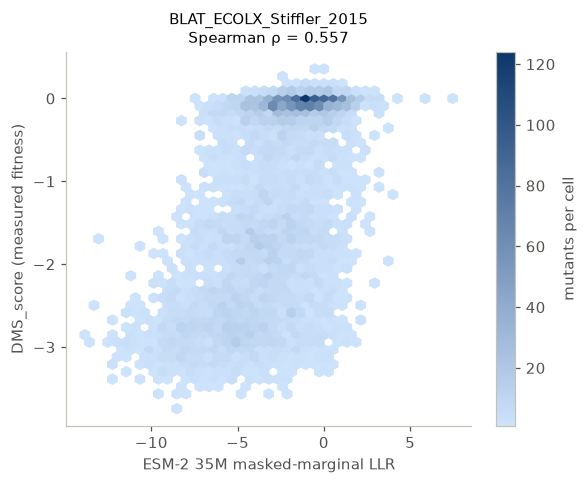

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
hb = ax.hexbin(dms[f"esm_{MAIN_MODEL}"], dms["DMS_score"], gridsize=40, mincnt=1,
               cmap=LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#0d366b"]))
plt.colorbar(hb, ax=ax, label="mutants per cell")
ax.set_xlabel(f"ESM-2 {MAIN_MODEL} masked-marginal LLR"); ax.set_ylabel("DMS_score (measured fitness)")
ax.set_title(f"{MAIN_ASSAY}\nSpearman ρ = {rho:.3f}", fontsize=10)
ax.grid(False); plt.tight_layout(); plt.savefig(FIGS / "blat_scatter.png", dpi=150); plt.show()

## 4. What does the model actually get right?

A global Spearman mixes two questions:
1. **Which positions are sensitive?** (buried core, active site vs. surface loop)
2. **Within a position, which substitutions are worse?** (e.g. L→I vs L→D)

Side-by-side heatmaps show the full mutational landscape. Then we split the correlation into these two parts.

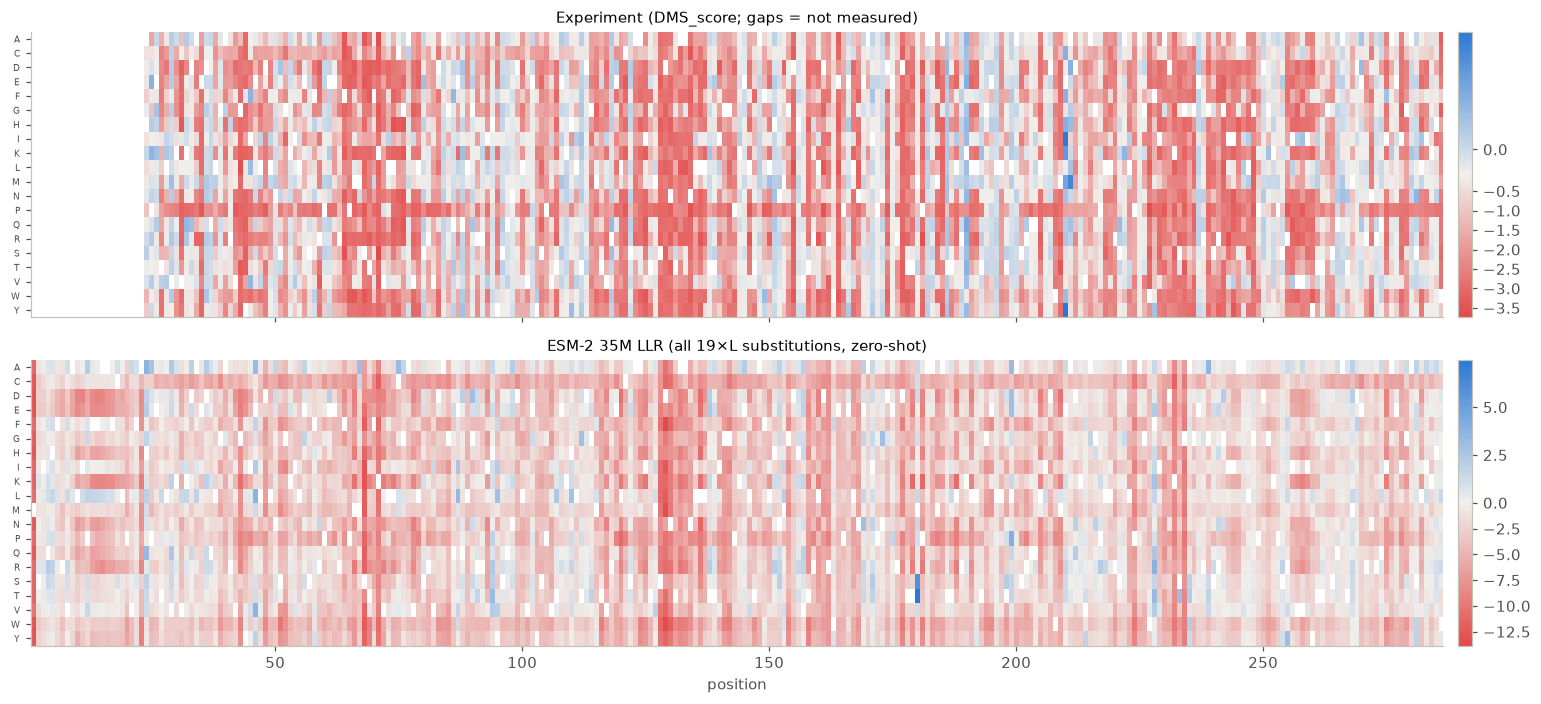

In [8]:
def dms_matrix(df, L):
    m = np.full((L, 20), np.nan)
    m[df["pos"].values - 1, [AAS.index(a) for a in df["mt"]]] = df["DMS_score"].values
    return m

L = len(wt_seq)
llr = llr_matrix(lp, wt_seq)
exp_m = dms_matrix(dms, L)
wt_dms = np.nanmedian(dms.loc[dms["DMS_score_bin"] == 1, "DMS_score"])   # centre the colour scale on "wt-like"

fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
ext = (0.5, L + 0.5, 19.5, -0.5)                                   # x axis = 1-based residue number
im0 = axes[0].imshow(exp_m.T, aspect="auto", cmap=DIVERGING, interpolation="nearest", extent=ext,
                     norm=TwoSlopeNorm(vcenter=wt_dms, vmin=np.nanmin(exp_m), vmax=np.nanmax(exp_m)))
axes[0].set_title("Experiment (DMS_score; gaps = not measured)", fontsize=10)
model_m = llr.copy(); model_m[np.arange(L), [AAS.index(a) for a in wt_seq]] = np.nan
im1 = axes[1].imshow(model_m.T, aspect="auto", cmap=DIVERGING, interpolation="nearest", extent=ext,
                     norm=TwoSlopeNorm(vcenter=0, vmin=np.nanmin(model_m), vmax=max(1, np.nanmax(model_m))))
axes[1].set_title(f"ESM-2 {MAIN_MODEL} LLR (all 19×L substitutions, zero-shot)", fontsize=10)
for ax, im in zip(axes, [im0, im1]):
    ax.set_yticks(range(20)); ax.set_yticklabels(AAS, fontsize=6); ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.015, pad=0.01)
axes[1].set_xlabel("position")
plt.tight_layout(); plt.savefig(FIGS / "blat_heatmaps.png", dpi=150); plt.show()

global ρ (all mutants)                     : 0.557
between positions (per-site mean score)     : 0.583   (263 positions)
within a position (median over 263 sites) : 0.463


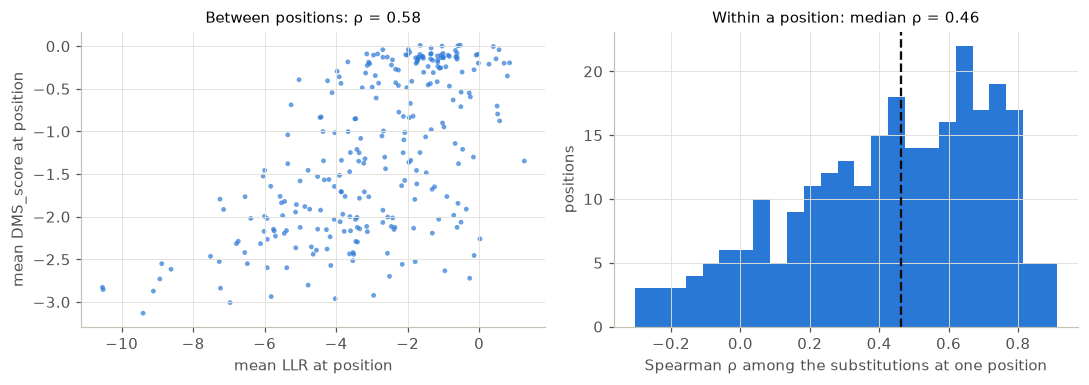

In [9]:
col = f"esm_{MAIN_MODEL}"
per_pos = dms.groupby("pos").agg(model=(col, "mean"), exp=("DMS_score", "mean"), n=("DMS_score", "size"))
rho_site = spearmanr(per_pos["model"], per_pos["exp"])[0]

within = [spearmanr(g[col], g["DMS_score"])[0] for _, g in dms.groupby("pos")
          if len(g) >= 10 and g["DMS_score"].nunique() > 1]
within = np.array([w for w in within if np.isfinite(w)])

print(f"global ρ (all mutants)                     : {rho:.3f}")
print(f"between positions (per-site mean score)     : {rho_site:.3f}   ({len(per_pos)} positions)")
print(f"within a position (median over {len(within)} sites) : {np.median(within):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(per_pos["model"], per_pos["exp"], s=10, color=C1, alpha=0.7, edgecolor="none")
axes[0].set_xlabel("mean LLR at position"); axes[0].set_ylabel("mean DMS_score at position")
axes[0].set_title(f"Between positions: ρ = {rho_site:.2f}", fontsize=10)
axes[1].hist(within, bins=25, color=C1)
axes[1].axvline(np.median(within), color="#0b0b0b", lw=1.5, ls="--")
axes[1].set_xlabel("Spearman ρ among the substitutions at one position"); axes[1].set_ylabel("positions")
axes[1].set_title(f"Within a position: median ρ = {np.median(within):.2f}", fontsize=10)
plt.tight_layout(); plt.savefig(FIGS / "blat_site_vs_within.png", dpi=150); plt.show()

## 5. Does a bigger model help?

Same assay, four ESM-2 sizes. Published ProteinGym values are plotted next to ours. (The 650M scan takes ~9 min on CPU the
first time; set `RUN_650M = False` in §0 to skip it.)

In [10]:
sizes = [s for s in MODELS if s != "650M" or RUN_650M]
rows = []
for s in sizes:
    t0 = time.time()
    dms[f"esm_{s}"] = score_mutants(dms, llr_matrix(cached_logprobs(MAIN_ASSAY, wt_seq, s), wt_seq))
    r, lo, hi, auc = evaluate(dms, f"esm_{s}")
    rows.append(dict(model=s, ours=r, ci_lo=lo, ci_hi=hi, auc=auc,
                     published=published.loc[MAIN_ASSAY, f"ESM2 ({s})"]))
scaling = pd.DataFrame(rows).set_index("model")
scaling.round(3)

,ours,ci_lo,ci_hi,auc,published
model,,,,,
8M,0.399,0.376,0.421,0.704,0.399
35M,0.557,0.537,0.577,0.782,0.557
150M,0.661,0.644,0.677,0.839,0.661
650M,0.731,0.717,0.746,0.883,0.731


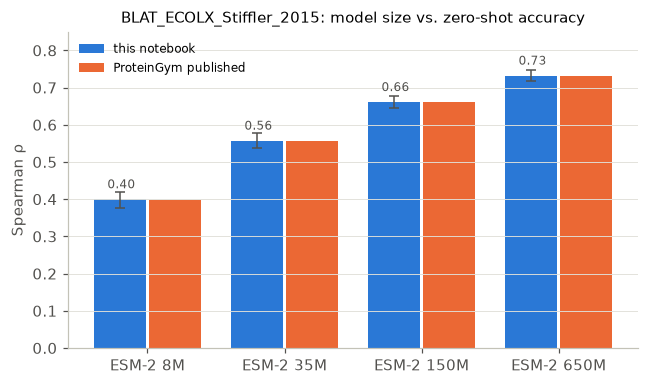

In [11]:
x = np.arange(len(scaling)); w = 0.38
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(x - w/2 - 0.01, scaling["ours"], w, color=C1, label="this notebook",
       yerr=[scaling["ours"] - scaling["ci_lo"], scaling["ci_hi"] - scaling["ours"]],
       error_kw=dict(ecolor="#52514e", lw=1, capsize=3))
ax.bar(x + w/2 + 0.01, scaling["published"], w, color=C2, label="ProteinGym published")
for xi, v in zip(x, scaling["ours"]):
    ax.text(xi - w/2, v + 0.03, f"{v:.2f}", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x); ax.set_xticklabels([f"ESM-2 {s}" for s in scaling.index])
ax.set_ylabel("Spearman ρ"); ax.set_ylim(0, 0.85); ax.grid(axis="x", visible=False)
ax.set_title(f"{MAIN_ASSAY}: model size vs. zero-shot accuracy", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIGS / "blat_scaling.png", dpi=150); plt.show()

## 6. A cheaper score, and non-ML baselines

**Wild-type marginal** (Meier et al., 2021): run the *unmasked* sequence once and read probabilities at every position.
One forward pass instead of *L*. It is slightly biased toward the wild-type residue (the model can see it), but often
close in accuracy.

Two baselines that use no protein language model at all — a model must beat these to be interesting:
* **BLOSUM62** substitution score: generic amino-acid exchangeability, same for every protein and position.
* **Hydrophobicity change** (|ΔKyte–Doolittle|): larger change → predicted worse.

In [12]:
_B62 = '''
   A  R  N  D  C  Q  E  G  H  I  L  K  M  F  P  S  T  W  Y  V
A  4 -1 -2 -2  0 -1 -1  0 -2 -1 -1 -1 -1 -2 -1  1  0 -3 -2  0
R -1  5  0 -2 -3  1  0 -2  0 -3 -2  2 -1 -3 -2 -1 -1 -3 -2 -3
N -2  0  6  1 -3  0  0  0  1 -3 -3  0 -2 -3 -2  1  0 -4 -2 -3
D -2 -2  1  6 -3  0  2 -1 -1 -3 -4 -1 -3 -3 -1  0 -1 -4 -3 -3
C  0 -3 -3 -3  9 -3 -4 -3 -3 -1 -1 -3 -1 -2 -3 -1 -1 -2 -2 -1
Q -1  1  0  0 -3  5  2 -2  0 -3 -2  1  0 -3 -1  0 -1 -2 -1 -2
E -1  0  0  2 -4  2  5 -2  0 -3 -3  1 -2 -3 -1  0 -1 -3 -2 -2
G  0 -2  0 -1 -3 -2 -2  6 -2 -4 -4 -2 -3 -3 -2  0 -2 -2 -3 -3
H -2  0  1 -1 -3  0  0 -2  8 -3 -3 -1 -2 -1 -2 -1 -2 -2  2 -3
I -1 -3 -3 -3 -1 -3 -3 -4 -3  4  2 -3  1  0 -3 -2 -1 -3 -1  3
L -1 -2 -3 -4 -1 -2 -3 -4 -3  2  4 -2  2  0 -3 -2 -1 -2 -1  1
K -1  2  0 -1 -3  1  1 -2 -1 -3 -2  5 -1 -3 -1  0 -1 -3 -2 -2
M -1 -1 -2 -3 -1  0 -2 -3 -2  1  2 -1  5  0 -2 -1 -1 -1 -1  1
F -2 -3 -3 -3 -2 -3 -3 -3 -1  0  0 -3  0  6 -4 -2 -2  1  3 -1
P -1 -2 -2 -1 -3 -1 -1 -2 -2 -3 -3 -1 -2 -4  7 -1 -1 -4 -3 -2
S  1 -1  1  0 -1  0  0  0 -1 -2 -2  0 -1 -2 -1  4  1 -3 -2 -2
T  0 -1  0 -1 -1 -1 -1 -2 -2 -1 -1 -1 -1 -2 -1  1  5 -2 -2  0
W -3 -3 -4 -4 -2 -2 -3 -2 -2 -3 -2 -3 -1  1 -4 -3 -2 11  2 -3
Y -2 -2 -2 -3 -2 -1 -2 -3  2 -1 -1 -2 -1  3 -3 -2 -2  2  7 -1
V  0 -3 -3 -3 -1 -2 -2 -3 -3  3  1 -2  1 -1 -2 -2  0 -3 -1  4
'''
BLOSUM62 = pd.read_csv(io.StringIO(_B62), sep=r"\s+", index_col=0)
KD = dict(A=1.8, R=-4.5, N=-3.5, D=-3.5, C=2.5, Q=-3.5, E=-3.5, G=-0.4, H=-3.2, I=4.5,
          L=3.8, K=-3.9, M=1.9, F=2.8, P=-1.6, S=-0.8, T=-0.7, W=-0.9, Y=-1.3, V=4.2)

dms["blosum62"] = [BLOSUM62.loc[w, m] for w, m in zip(dms["wt"], dms["mt"])]
dms["neg_dhydro"] = [-abs(KD[m] - KD[w]) for w, m in zip(dms["wt"], dms["mt"])]

rows = [("BLOSUM62", "blosum62"), ("−|Δ hydrophobicity|", "neg_dhydro")]
for s in ["8M", "35M", "150M"]:
    dms[f"wt_{s}"] = score_mutants(dms, llr_matrix(cached_logprobs(MAIN_ASSAY, wt_seq, s, masked=False), wt_seq))
    rows += [(f"ESM-2 {s} wt-marginal", f"wt_{s}"), (f"ESM-2 {s} masked-marginal", f"esm_{s}")]

compare = pd.DataFrame([(name, *evaluate(dms, c)) for name, c in rows],
                       columns=["score", "spearman", "ci_lo", "ci_hi", "auc"]).set_index("score")
compare.round(3)

,spearman,ci_lo,ci_hi,auc
score,,,,
BLOSUM62,0.346,0.321,0.371,0.673
−|Δ hydrophobicity|,0.191,0.164,0.219,0.599
ESM-2 8M wt-marginal,0.374,0.350,0.396,0.691
ESM-2 8M masked-marginal,0.399,0.376,0.421,0.704
ESM-2 35M wt-marginal,0.520,0.500,0.541,0.764
ESM-2 35M masked-marginal,0.557,0.537,0.577,0.782
ESM-2 150M wt-marginal,0.641,0.625,0.658,0.831
ESM-2 150M masked-marginal,0.661,0.644,0.677,0.839


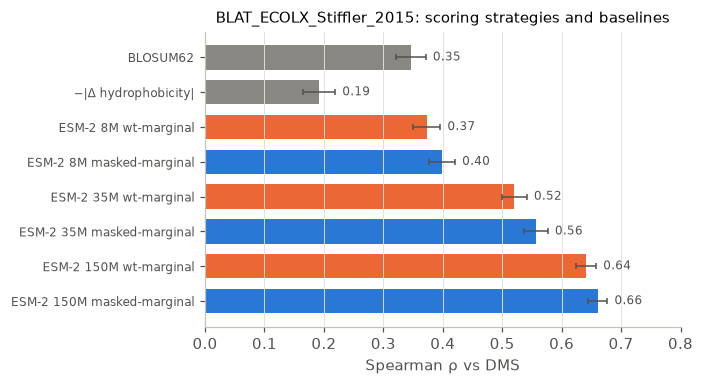

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
colors = [MUTED if "ESM" not in n else (C2 if "wt-marginal" in n else C1) for n in compare.index]
y = np.arange(len(compare))[::-1]
ax.barh(y, compare["spearman"], color=colors, height=0.7,
        xerr=[compare["spearman"] - compare["ci_lo"], compare["ci_hi"] - compare["spearman"]],
        error_kw=dict(ecolor="#52514e", lw=1, capsize=2))
for yi, v, hi in zip(y, compare["spearman"], compare["ci_hi"]):
    ax.text(hi + 0.012, yi, f"{v:.2f}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y); ax.set_yticklabels(compare.index, fontsize=8)
ax.set_xlabel("Spearman ρ vs DMS"); ax.set_xlim(0, 0.8); ax.grid(axis="y", visible=False)
ax.set_title(f"{MAIN_ASSAY}: scoring strategies and baselines", fontsize=10)
plt.tight_layout(); plt.savefig(FIGS / "blat_baselines.png", dpi=150); plt.show()

## 7. Beyond one protein: a nine-assay panel

One assay can flatter or punish a method. We score eight more ProteinGym assays (single-mutant-only, ≤ 300 aa, a mix of
organismal fitness / activity / expression / stability, bacteria / human / virus) with ESM-2 35M and 150M, and compare with the
published values. Several were chosen because ESM-2 is known to **struggle** on them. First run ≈ 10 min (mostly 150M).

In [14]:
PANEL = ["BLAT_ECOLX_Stiffler_2015", "DYR_ECOLI_Nguyen_2023", "TPMT_HUMAN_Matreyek_2018",
         "RASH_HUMAN_Bandaru_2017", "ESTA_BACSU_Nutschel_2020", "UBC9_HUMAN_Weile_2017",
         "CCDB_ECOLI_Tripathi_2016", "SYUA_HUMAN_Newberry_2020", "REV_HV1H2_Fernandes_2016"]
PANEL_MODELS = ["35M", "150M"]

rows = []
for a in PANEL:
    seq, df = ref.loc[a, "target_seq"], load_assay(a)
    check_wt(df, seq)
    for s in PANEL_MODELS:
        df[s] = score_mutants(df, llr_matrix(cached_logprobs(a, seq, s), seq))
        rows.append(dict(assay=a, model=s, length=len(seq), n_mutants=len(df),
                         selection=ref.loc[a, "coarse_selection_type"], taxon=ref.loc[a, "taxon"],
                         ours=spearmanr(df[s], df["DMS_score"])[0],
                         published=published.loc[a, f"ESM2 ({s})"]))
panel = pd.DataFrame(rows)
panel.pivot_table(index=["assay", "selection", "taxon", "length"], columns="model",
                  values=["ours", "published"]).round(3)

ours         \
model                                                          150M    35M   
assay                    selection         taxon      length                 
BLAT_ECOLX_Stiffler_2015 OrganismalFitness Prokaryote 286     0.661  0.557   
CCDB_ECOLI_Tripathi_2016 OrganismalFitness Prokaryote 101     0.462 -0.001   
DYR_ECOLI_Nguyen_2023    OrganismalFitness Prokaryote 159     0.525  0.500   
ESTA_BACSU_Nutschel_2020 Stability         Prokaryote 212     0.267  0.270   
RASH_HUMAN_Bandaru_2017  Activity          Human      189     0.487  0.514   
REV_HV1H2_Fernandes_2016 OrganismalFitness Virus      116     0.173  0.046   
SYUA_HUMAN_Newberry_2020 OrganismalFitness Human      140     0.150  0.142   
TPMT_HUMAN_Matreyek_2018 Expression        Human      245     0.531  0.433   
UBC9_HUMAN_Weile_2017    OrganismalFitness Human      159     0.403  0.004   

                                                             published         
model                                                             150M    35M  
assay                    selection         taxon      length                   
BLAT_ECOLX_Stiffler_2015 OrganismalFitness Prokaryote 286        0.661  0.557  
CCDB_ECOLI_Tripathi_2016 OrganismalFitness Prokaryote 101        0.462 -0.001  
DYR_ECOLI_Nguyen_2023    OrganismalFitness Prokaryote 159        0.525  0.500  
ESTA_BACSU_Nutschel_2020 Stability         Prokaryote 212        0.267  0.270  
RASH_HUMAN_Bandaru_2017  Activity          Human      189        0.487  0.514  
REV_HV1H2_Fernandes_2016 OrganismalFitness Virus      116        0.173  0.046  
SYUA_HUMAN_Newberry_2020 OrganismalFitness Human      140        0.150  0.142  
TPMT_HUMAN_Matreyek_2018 Expression        Human      245        0.531  0.433  
UBC9_HUMAN_Weile_2017    OrganismalFitness Human      159        0.403  0.004

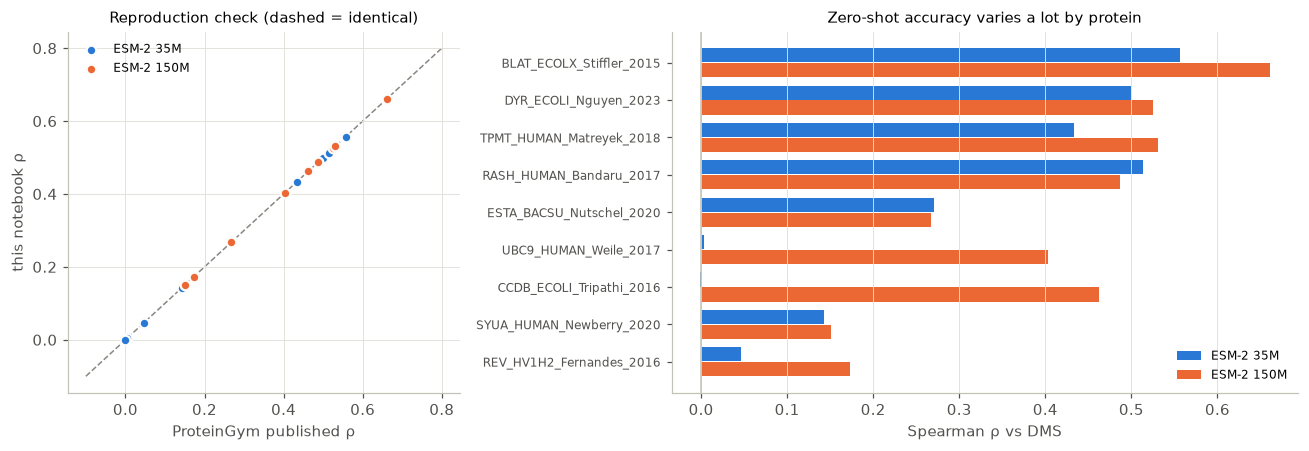

mean ρ over panel: {'150M': 0.407, '35M': 0.274}


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1, 1.6]))
ax = axes[0]
for s, c in zip(PANEL_MODELS, [C1, C2]):
    g = panel[panel["model"] == s]
    ax.scatter(g["published"], g["ours"], s=40, color=c, label=f"ESM-2 {s}",
               edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
ax.plot([-0.1, 0.8], [-0.1, 0.8], color=MUTED, lw=1, ls="--", zorder=1)
ax.set_xlabel("ProteinGym published ρ"); ax.set_ylabel("this notebook ρ")
ax.set_title("Reproduction check (dashed = identical)", fontsize=10)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
wide = panel.pivot(index="assay", columns="model", values="ours").loc[PANEL]
y = np.arange(len(wide))[::-1]; h = 0.38
for k, (s, c) in enumerate(zip(PANEL_MODELS, [C1, C2])):
    ax.barh(y + (h/2 + 0.01) * (1 if k == 0 else -1), wide[s], h, color=c, label=f"ESM-2 {s}")
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set_yticks(y); ax.set_yticklabels(wide.index, fontsize=8)
ax.set_xlabel("Spearman ρ vs DMS"); ax.grid(axis="y", visible=False)
ax.set_title("Zero-shot accuracy varies a lot by protein", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIGS / "panel.png", dpi=150); plt.show()

print("mean ρ over panel:", panel.groupby("model")["ours"].mean().round(3).to_dict())

## 8. Takeaways

*Filled in from the numbers above — see README.md for the discussion.*

* **Sequence statistics carry fitness signal.** With no labels and no training, a 35M-parameter model ranks ~5,000 β-lactamase
  mutants with Spearman ρ ≈ 0.55; the 650M model reaches ≈ 0.73.
* **It knows both *where* and *what*.** Averaged per position, model and experiment agree on which sites are sensitive
  (ρ ≈ 0.58). Within a single position the model still ranks the 19 substitutions reasonably (median ρ ≈ 0.46), so it is not just
  flagging "important sites". The N-terminal signal peptide (residues 1–23) was not mutated in the experiment, but the model
  scores it anyway.
* **Bigger is better on average, but not everywhere.** Small models can fail outright on some proteins (UBC9, CcdB: ρ ≈ 0
  at 35M), and some assays (α-synuclein, HIV Rev) stay hard for every size.
* **Benchmark hygiene:** check the wild-type alignment, use rank correlation, report a confidence interval, compare to a simple
  baseline, reproduce a published number before trusting your own, and look at more than one assay.